In [2]:
# imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import torch
from skimage import io
from glob import glob
import anndata as ad
import scanpy as sc
import seaborn as sns
import awkward as ak
import pickle

%load_ext autoreload
%autoreload 2

In [3]:
# Add base dir to path
import sys
sys.path.insert(0, '../')

In [4]:
# Make color palette for all groups we'll come across
tmp_patterns = ["small-intestine","random", "intranuclear", "nuclear-edge", "extranuclear", "foci", "protrusion", "cell-edge", "perinuclear", 
                         "pericellular","pattern"]
def get_cmap(n, name='tab10'):
    ##Returns a function that maps each index in 0, 1, ..., n-1 to a distinct 
    ##RGB color; the keyword argument name must be a standard mpl colormap name.
    return plt.cm.get_cmap(name, n)

global_cmap = get_cmap(len(tmp_patterns))
# cmap = get_cmap(len(adata.obs["pattern"].unique()), name="tab10")
palette = {}
for i, el in enumerate(tmp_patterns):
    palette[el] =  global_cmap(i)
    
colorblind_palette = sns.color_palette("colorblind")

In [5]:
# tmp pointer to acutal data, remove before committing
simulation_dir = Path("/mnt/data/david/simulated_cells/templates/")
data_dir = Path("/mnt/data/david/subcellspace_data/")

In [6]:
# Make sure seed is the same at all times, in all packages that use it
seed = 101
torch.manual_seed(seed)
import random
random.seed(seed)
np.random.seed(seed)

In [ ]:
simulation_dir = Path("/path/to/output/of/simulations/") # output of training_subcellspace/create_simulations/

In [ ]:
data_dir = Path("path/to/data/dir/")

In [6]:
subcellspace = torch.load("../SubCellSpace")

In [7]:
from src.adata_utils import convertRecordToDf, decodeSubcellEmbedding, getAllDetectedTranscripts, getXYOfSingleCell, reshape_and_filter_anndata_with_index_and_mapping
from src.plotting import plotFullDataPoint, saveAFigure

In [8]:
single_cell_adata = ad.read_h5ad(data_dir / "apex_validation_data" / "adata_subcell_including_randomized_embeddings.h5ad")

/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/anndata/_core/aligned_mapping.py:54: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  warnings.warn(


In [9]:
single_cell_adata

AnnData object with n_obs × n_vars = 154296 × 541
    obs: 'name', 'tile_nr', 'local_row', 'local_col', 'cell_id', 'global_row', 'global_col', 'cell_size'
    var: 'gene_name', 'gene_label'
    uns: 'measured_df'
    obsm: 'cell_mask', 'dapi_mask', 'detected_transcripts'
    layers: 'random_subcell_embedding', 'subcell_embedding'

In [10]:
adata = ad.read_h5ad(data_dir / "apex_validation_data" / "adata_subcell_embeddings_classified_and_subtypes.h5ad")

In [11]:
random_adata = reshape_and_filter_anndata_with_index_and_mapping(single_cell_adata, layer="random_subcell_embedding")

# Fig 4A: Power analysis

In [21]:
from src.dataprep import initialize_adata, create_simulated_gene
# from src.classifiers import classify_all_genes, loadPatternClassifier, loadPatternNoPatternClassifier, classifyAllGenes

In [22]:
from src.dataprep import initialize_adata, create_simulated_gene

In [23]:
from src.power_analysis import compute_power_rf

In [24]:
path = '../classifiers/rf_pattern_nonpattern.pkl'
with open(path, 'rb') as p:
    classifier = pickle.load(p)

adata_split_cellID = sc.read_h5ad(data_dir / "simulated_data" / "power_analysis_data" / "custom_power_analysis_panel.h5ad")
adata_shuffled = sc.read_h5ad(data_dir / "simulated_data" / "power_analysis_data" / "custom_power_analyis_panel_randomized.h5ad")
adata_split_cellID = initialize_adata(adata_split_cellID)
adata_shuffled = initialize_adata(adata_shuffled)
adata_split_cellID.obs["cell_id"] = adata_split_cellID.obs["cell_id"].astype(int) 
adata_shuffled.obs["cell_id"] = adata_shuffled.obs["cell_id"].astype(int) 
test_cell_ids =list(pd.read_csv(data_dir / "simulated_data" / "test_cell_ids.csv", header=None)[0])
adata_test = adata_split_cellID[adata_split_cellID.obs['cell_id'].isin(test_cell_ids)]
adata_test_shuffled = adata_shuffled[adata_shuffled.obs['cell_id'].isin(test_cell_ids)]

assert len(adata_test) == len(adata_test_shuffled)

strengths = ['strong'] 
rna_counts =list( adata_test.obs['n_spots_interval'].unique())

# Generated 14 points between 5 and 7000 on a log scale:
# points = np.logspace(np.log10(5), np.log10(7000), num=14)
# cell_counts = np.round(points).astype(int) # output is separated by /t iso commas, so can't use directly in the code

cell_counts = [5, 9, 15, 27, 46, 81, 142, 247, 432, 753, 1315, 2297, 4009, 7000]

# Create a list of all combinations of strength, count, and cell_count
combinations = [(strength, rna_count, cell_count) for strength in strengths for rna_count in rna_counts for cell_count in cell_counts]
print(combinations)

results = [compute_power_rf(params, classifier, adata_test, adata_test_shuffled) for params in combinations]

# Convert the results to a dictionary
power_results = {result[0]: result[1] for result, _ in results if result}
bonferroni_power_results = {bonferroni_result[0]: bonferroni_result[1] for _, bonferroni_result in results if bonferroni_result}


KeyboardInterrupt



In [8]:
df = pd.read_csv(data_dir / "simulated_data" / "power_analysis_data" / 'power_rf.txt', sep='\t', names=['strength','rna_count', 'sample_size', 'power', 'bonferonni power'], index_col=False)
# df = pd.DataFrame(bonferroni_power_results)

In [9]:
df = df[df['power'] != -1].copy()
df['sample_size'] = df['sample_size'].astype(int)

In [10]:
df['rna_count'].unique()

array(['100+', '10-20', '20-30', '30-40', '40-50', '50-60', '70-80',
       '80-90', '90-100'], dtype=object)

In [11]:
from matplotlib.transforms import offset_copy
from scipy.interpolate import PchipInterpolator
from scipy.optimize import brentq

df.replace([np.inf, -np.inf], np.nan, inplace=True)
unique_sample_sizes = sorted(df['sample_size'].unique())
df.loc[:,'sample_size_index'] = df['sample_size'].apply(lambda x: unique_sample_sizes.index(x))

# Derive the RNA count bins from the data and order them by their lower bound, rather than
# hardcoding hue_order. seaborn silently DROPS any data level absent from hue_order, and the
# previous hardcoded list named bins ('10-20', '20-30', ...) that this dataset does not have:
# only 2 of the 5 bins were actually drawn, beneath a legend advertising 11 of them.
rna_count_order = sorted(df['rna_count'].unique(),
                         key=lambda b: int(b.rstrip('+').split('-')[0]))

# The bins are ordinal, so encode them with a sequential ramp instead of categorical hues:
# darker = higher RNA count, which reads straight off the curves without the legend. The ramp
# is truncated at 0.75 because the pale end of the full ramp washes out on white; this keeps
# every bin at a contrast ratio >= 1.6 against the background.
rna_count_palette = [tuple(c) for c in sns.color_palette("crest_r", as_cmap=True)(
    np.linspace(0.0, 0.75, len(rna_count_order)))][::-1]

# Create three plots with different pattern strengths
g = sns.relplot(
    data=df, 
    x="sample_size_index", 
    y="power", 
    hue="rna_count",
    hue_order = rna_count_order,
    palette=rna_count_palette,
    col="strength",
    kind="line",
    markers=True,       # Enable markers
    marker='o',         # Circle markers at each measurement point
)
g.set_axis_labels("Cell Count", "Power")
g.set_titles("{col_name} Pattern Strength")
g.tight_layout(w_pad=1)
g.legend.set_title("RNA Count")

# Set global font size parameters
plt.rc('axes', titlesize=17)     # Font size for titles
plt.rc('axes', labelsize=17)     # Font size for x and y labels
plt.rc('xtick', labelsize=17)    # Font size for x tick labels
plt.rc('ytick', labelsize=15)    # Font size for y tick labels
plt.rc('legend', fontsize=16)    # Font size for legend
plt.rc('legend', title_fontsize=17)    # Font size for legend title

# Function to set custom x-scale
def set_custom_xscale(ax, unique_vals):
    ax.set_xticks(range(len(unique_vals)))
    ax.set_xticklabels(unique_vals, rotation=90)
    ax.set_xlim(-0.5, len(unique_vals) - 0.5)
    ax.grid(True, linewidth=0.5)

# Cutoff used for the reported minimum cell count. 0.8 is not arbitrary: it is where the
# fitted logistic power curve has its elbow (see the cutoff analysis in the next cells).
POWER_THRESHOLD = 0.8

def crossing_cell_count(bin_label, threshold):
    """Cell count at which this RNA count bin's power curve reaches `threshold`.

    Monotone (PCHIP) interpolation on log10(cell count) -- deliberately the same estimator as
    n_at_power() in the cutoff table below, so the figure and the table cannot disagree.
    """
    sub = df[df['rna_count'] == bin_label].sort_values('sample_size')
    n = sub['sample_size'].values
    y = np.maximum.accumulate(sub['power'].values)   # enforce monotonicity against MC noise
    if y[0] >= threshold:
        return float(n[0])
    if y[-1] < threshold:
        return np.nan
    f = PchipInterpolator(np.log10(n), y)
    return 10 ** brentq(lambda t: f(t) - threshold, np.log10(n[0]), np.log10(n[-1]))


def cell_count_to_x(n, unique_vals):
    """Map a cell count onto the categorical x axis, whose ticks are geometric in cell count."""
    return float(np.interp(np.log10(n), np.log10(unique_vals), np.arange(len(unique_vals))))


ELBOW_COLOUR = '#b3452c'   # warm accent, reads against the cool crest palette


# Function to put the elbow cell count on the x axis as its own emphasized tick
def add_elbow_xtick(ax, threshold, order, unique_vals):
    """Add the exact cutoff cell count to the x axis, emphasized.

    Reports the median across RNA count bins, i.e. the typical bin. Swap np.nanmedian() for
    max() to report the worst (lowest RNA count) bin instead, the conservative choice.
    nanmedian rather than median so a bin that never reaches the threshold is skipped, matching
    how the pandas .median() in the cutoff table below treats it.

    The axis is categorical: its positions are indices over a geometric grid of cell counts, so
    the elbow is placed by interpolating on log10(cell count), i.e. where it would fall on a
    true log axis. The label goes on a second row beneath the regular ones (a minor tick with an
    enlarged pad) so that no standard tick has to be dropped to make room for it -- at this
    font size a rotated label occupies most of an index unit, so a co-located major tick would
    collide with the grid labels either side of it.
    """
    n = float(np.ceil(np.nanmedian([crossing_cell_count(b, threshold) for b in order])))
    x = cell_count_to_x(n, unique_vals)

    # accent line from the axis up to the threshold, meeting the horizontal line at the elbow
    y0 = ax.get_ylim()[0]
    ax.vlines(x, y0, threshold, color=ELBOW_COLOUR, linestyle='--', linewidth=1.8, zorder=1.5)
    ax.set_ylim(bottom=y0)                       # vlines would otherwise pad the data limits

    # measure the regular labels so the emphasized one clears them, whatever the font size
    ax.figure.canvas.draw()
    renderer = ax.figure.canvas.get_renderer()
    row_px = max(t.get_window_extent(renderer).height for t in ax.get_xticklabels())
    pad = row_px * 72 / ax.figure.dpi + 4        # px -> points, plus a small gap

    ax.set_xticks([x], minor=True)
    ax.set_xticklabels([f'{n:.0f}'], minor=True, rotation=90)
    ax.tick_params(axis='x', which='minor', pad=pad, length=9, width=2.2,
                   color=ELBOW_COLOUR, labelcolor=ELBOW_COLOUR, labelsize=17)
    ax.get_xticklabels(minor=True)[0].set_fontweight('bold')
    return n, x


# Function to draw the power cutoff as a horizontal reference line
def add_power_threshold(ax, threshold):
    # zorder between the grid and the data lines, and kept out of the RNA count legend
    ax.axhline(threshold, color='0.35', linestyle='--', linewidth=1.8,
               zorder=1.5, label='_nolegend_')
    # x in axes fraction, y in data units, then nudged up by a fixed 6 pt so the gap to the
    # line does not depend on the y-limits
    # Right-aligned at the right edge: the curves cross the threshold on the LEFT of the plot,
    # so a left-aligned label gets struck through by them, whereas the region between the
    # threshold and the saturated plateau on the right is empty.
    label_tf = offset_copy(ax.get_yaxis_transform(), fig=ax.figure, x=0, y=6, units='points')
    ax.text(0.985, threshold, f'{threshold:.0%} power', transform=label_tf,
            color='0.35', fontsize=15, ha='right', va='bottom')

# Rotate x-axis labels for each subplot
for ax in g.axes.flatten():
    set_custom_xscale(ax, unique_sample_sizes)
    add_power_threshold(ax, POWER_THRESHOLD)
    add_elbow_xtick(ax, POWER_THRESHOLD, rna_count_order, unique_sample_sizes)
    
# Show the plot
# saved without tight_layout, which squeezes the FacetGrid under its outside legend
for ext, dpi in (("png", 1200), ("svg", 300)):
    g.figure.savefig(f"/mnt/data/david/plots/manuscript/quantification/power_analysis.{ext}", dpi=dpi, bbox_inches="tight")
plt.show()

/tmp/ipykernel_2503988/993798891.py:147: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show()


In [12]:
from scipy.interpolate import PchipInterpolator
from scipy.optimize import curve_fit, brentq

N_REP = 1000      # replicates per (rna_count, cell_count) point in compute_power_rf
ALPHA = 0.05      # uncorrected significance level -> power floor of the curve


def n_at_power(cell_counts, power, target):
    """Smallest cell count reaching `target` power, monotone interpolation on log10(n)."""
    x = np.log10(cell_counts)
    y = np.maximum.accumulate(power)   # power is monotone in n; enforce against MC noise
    if y[0] >= target:
        return cell_counts[0]
    if y[-1] < target:
        return np.nan
    f = PchipInterpolator(x, y)
    return 10 ** brentq(lambda t: f(t) - target, x[0], x[-1])


def knee_kneedle(cell_counts, power):
    """Kneedle elbow on (log10 n, power), with the saturated plateau trimmed first."""
    x, y = np.log10(cell_counts), np.maximum.accumulate(power)
    i = int(np.argmax(y >= y.max() - 1e-12))
    x, y = x[:i + 1], y[:i + 1]
    if len(x) < 3:
        return np.nan, np.nan
    f = PchipInterpolator(x, y)
    xg = np.linspace(x.min(), x.max(), 4001)
    xn = (xg - x.min()) / (x.max() - x.min())
    yn = (f(xg) - y.min()) / (y.max() - y.min())
    j = int(np.argmax(yn - xn))
    return 10 ** xg[j], float(f(xg[j]))


def logistic_elbow(cell_counts, power, alpha=ALPHA):
    """Fit power = alpha + (1-alpha)*logistic(log10 n); return the upper max-curvature point."""
    x, y = np.log10(cell_counts), np.maximum.accumulate(power)
    fn = lambda t, x0, k: alpha + (1 - alpha) / (1 + np.exp(-k * (t - x0)))
    (x0, k), _ = curve_fit(fn, x, y, p0=[1.0, 5.0], maxfev=40000)
    x_elbow = x0 + np.log(2 + np.sqrt(3)) / k          # where f''' = 0, i.e. s = (3+sqrt(3))/6
    return dict(n_elbow=10 ** x_elbow, power_at_elbow=float(fn(x_elbow, x0, k)),
                n_midpoint=10 ** x0, slope=k,
                rmse=float(np.sqrt(np.mean((fn(x, x0, k) - y) ** 2))))


def summarise_cutoffs(power_col, targets=(0.5, 0.8, 0.9, 0.95), n_boot=2000, seed=0):
    """Per-RNA-count-bin cutoffs, Monte-Carlo CIs, and both elbow estimates."""
    rng = np.random.default_rng(seed)
    rows = []
    for bin_label in rna_count_order:
        sub = df[df['rna_count'] == bin_label].sort_values('sample_size')
        n, y = sub['sample_size'].values, sub[power_col].values
        row = {'rna_count': bin_label}
        for t in targets:
            row[f'n_p{int(t * 100)}'] = n_at_power(n, y, t)
        # propagate binomial uncertainty of each power estimate onto the 0.8/0.9 cutoffs
        for t in (0.8, 0.9):
            b = [n_at_power(n, rng.binomial(N_REP, np.clip(y, 0, 1)) / N_REP, t)
                 for _ in range(n_boot)]
            row[f'n_p{int(t * 100)}_lo'], row[f'n_p{int(t * 100)}_hi'] = \
                np.nanpercentile(b, [2.5, 97.5])
        row['knee'], row['power_at_knee'] = knee_kneedle(n, y)
        row.update({k: v for k, v in logistic_elbow(n, y).items()
                    if k in ('n_elbow', 'power_at_elbow', 'rmse')})
        rows.append(row)
    return pd.DataFrame(rows).set_index('rna_count')


summary_raw = summarise_cutoffs('power')
summary_bonf = summarise_cutoffs('bonferonni power')

print('Uncorrected power (alpha = 0.05) -- the curve plotted above')
print(summary_raw.round(2).to_string())
print('\nBonferroni power (alpha = 0.05 / 5000)')
print(summary_bonf.round(2).to_string())

Uncorrected power (alpha = 0.05) -- the curve plotted above
           n_p50  n_p80  n_p90  n_p95  n_p80_lo  n_p80_hi  n_p90_lo  n_p90_hi   knee  power_at_knee  n_elbow  power_at_elbow  rmse
rna_count                                                                                                                         
10-20      10.41  19.69  23.52  28.06     19.04     20.31     22.75     24.44  25.20           0.93    18.57             0.8  0.03
20-30       7.76  14.06  18.69  22.06     13.26     15.00     17.77     19.49  13.68           0.79    12.95             0.8  0.02
30-40       8.00  15.69  19.62  22.28     14.69     16.55     18.86     20.25  21.06           0.93    13.86             0.8  0.02
40-50       7.64  12.42  16.10  19.31     11.97     12.94     15.11     17.03  14.21           0.86    11.97             0.8  0.01
50-60       6.52   9.85  12.95  16.57      9.35     10.29     12.29     13.86   9.31           0.77     9.61             0.8  0.01
70-80       6.51  10.11

In [13]:
# Headline numbers for the manuscript text. The worst bin is the lowest RNA count, i.e. the
# least detectable genes, so it is the conservative choice for a reported minimum cell count.
for name, s in [('Uncorrected (alpha=0.05)', summary_raw),
                ('Bonferroni (alpha=0.05/5000)', summary_bonf)]:
    worst = s['n_p80'].idxmax()
    print(name)
    for t in (50, 80, 90, 95):
        c = f'n_p{t}'
        print(f'  {t}% power : {np.ceil(s[c].median()):5.0f} cells (typical bin)'
              f'   {np.ceil(s.loc[worst, c]):5.0f} cells (worst bin, {worst} spots)')
    print(f'  Kneedle elbow sits at power {s["power_at_knee"].min():.2f}-{s["power_at_knee"].max():.2f}'
          f' (median {s["power_at_knee"].median():.2f})')
    print(f'  Logistic elbow sits at power {s["power_at_elbow"].median():.3f}'
          f'  -> equivalent to the 80% criterion; max fit RMSE {s["rmse"].max():.3f}')
    print()

# Caveat on grid resolution: the cell counts tested are spaced geometrically, so the 80%
# crossing for most bins falls inside a gap of the grid and rests on interpolation. Adding
# intermediate cell_counts to the sweep above would pin it down without interpolation.
print('tested cell counts:', sorted(df['sample_size'].unique()))

Uncorrected (alpha=0.05)
  50% power :     7 cells (typical bin)      11 cells (worst bin, 10-20 spots)
  80% power :    11 cells (typical bin)      20 cells (worst bin, 10-20 spots)
  90% power :    13 cells (typical bin)      24 cells (worst bin, 10-20 spots)
  95% power :    17 cells (typical bin)      29 cells (worst bin, 10-20 spots)
  Kneedle elbow sits at power 0.77-0.93 (median 0.86)
  Logistic elbow sits at power 0.799  -> equivalent to the 80% criterion; max fit RMSE 0.028

Bonferroni (alpha=0.05/5000)
  50% power :    26 cells (typical bin)      53 cells (worst bin, 10-20 spots)
  80% power :    36 cells (typical bin)      69 cells (worst bin, 10-20 spots)
  90% power :    40 cells (typical bin)      80 cells (worst bin, 10-20 spots)
  95% power :    44 cells (typical bin)      96 cells (worst bin, 10-20 spots)
  Kneedle elbow sits at power 0.90-0.97 (median 0.95)
  Logistic elbow sits at power 0.799  -> equivalent to the 80% criterion; max fit RMSE 0.022

tested cell counts

# Fig 4B

In [73]:
def find_threshold_x(x, y, threshold=0.0156):
    n = len(y)
    for i in range(n):
        if all(val >= threshold for val in y[i:]):
            return y[i]
    return None  # if no such point exists

In [90]:
def find_stable_x(x, y, epsilon=1e-4):
    n = len(y)
    for i in range(n):
        stable = True
        for j in range(i + 1, n):
            if y[j] < y[j - 1] - epsilon:
                stable = False
                break
        if stable:
            return x[i], y[i]
    return None  # no stable point found

In [70]:
sim_adata_of_all_proportions = ad.read_h5ad(simulation_dir / "adata_all_proportions_only_test.h5ad")
random_sim_adata_of_all_proportions = ad.read_h5ad(simulation_dir / "adata_all_proportions_only_test_randomized.h5ad")

In [77]:
high_prop_data = sim_adata_of_all_proportions[sim_adata_of_all_proportions.obs["prop"] >= 0.8]

high_random_adata = random_sim_adata_of_all_proportions[random_sim_adata_of_all_proportions.obs["prop"] >= 0.8]


In [40]:
from src.classifiers import quantify_gene_patterness

In [92]:
# Assume adata is your AnnData object
n_samples = 18
sample_size = 1000

# Check you have enough observations
assert high_random_adata.n_obs >= n_samples * 2 *sample_size, "Not enough cells in adata to create non-overlapping samples."

# Shuffle indices
all_indices = np.random.permutation(high_random_adata.n_obs)

index_of_permutations = 0

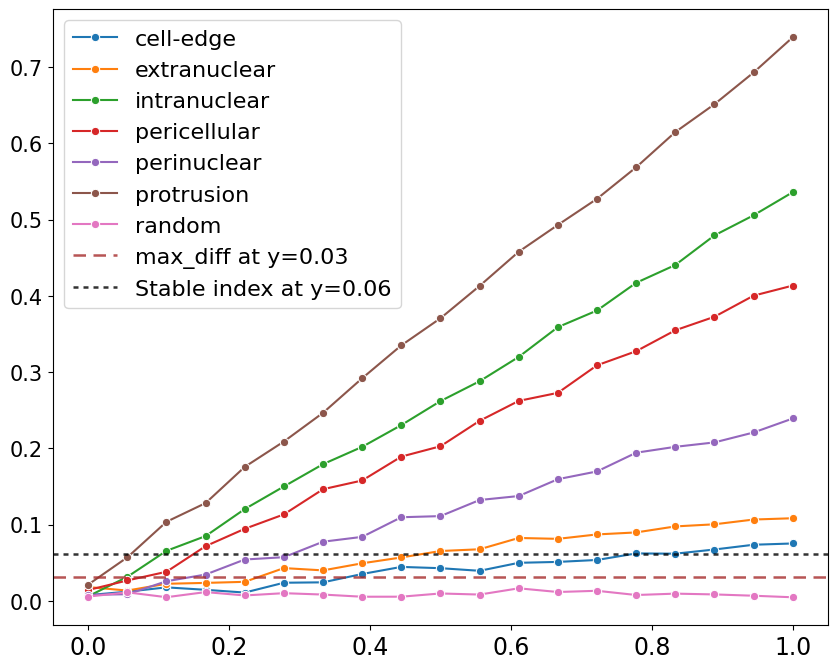

In [96]:
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    plt.rcParams["figure.figsize"] = [10,8]
    # n_steps = 18  # e.g., from 0% to 100% in 5% steps
    # max_obs = 1000  # Max number of observations per comparison

    max_diff = 0
    rows_list = []
    gene_counter = 0

    fig, axs = plt.subplots(1,1)

    for j, pattern in enumerate(high_prop_data.obs["pattern"].unique()):
        dist_dict = {}

        # Select high-proportion data for this pattern
        pattern_data = high_prop_data[(high_prop_data.obs["prop"] >= 0.5) & (high_prop_data.obs["pattern"] == pattern)]
        n_pattern = len(pattern_data)

        # Select enough random data for both mixing and baseline
        pattern_random = high_random_adata[high_random_adata.obs["pattern"] == pattern]
        n_random = len(pattern_random)

        # Determine max number of samples you can mix with no reuse
        total_needed = max_obs * (n_steps + 1)
        if n_pattern + n_random < total_needed:
            print(f"Warning: not enough data for {pattern} to avoid reuse completely.")

        # Shuffle both pools to avoid overlap bias
        rng = np.random.default_rng(seed=42)
        pattern_indices = rng.permutation(n_pattern)
        random_indices = rng.permutation(n_random)

        pattern_ptr = 0
        random_ptr = 0

        for step in range(n_steps + 1):
            gene_counter += 1
            attribute_dict = {}
            attribute_dict["gene_name"] = f"gene_{gene_counter}"
            attribute_dict["pattern"] = pattern
            attribute_dict["true_random"] = False
            proportion = step / n_steps  # from 0.0 to 1.0
            attribute_dict["proportion"] = proportion
            n_pat = int(max_obs * proportion)
            n_rand = max_obs - n_pat
            attribute_dict["n_pat"] = n_pat
            attribute_dict["n_rand"] = n_rand
            # Sample without replacement
            pat_samples = pattern_data[pattern_indices[pattern_ptr:pattern_ptr + n_pat]] if n_pat > 0 else None
            rand_samples = pattern_random[random_indices[random_ptr:random_ptr + n_rand]] if n_rand > 0 else None

            # Advance pointers to prevent reuse
            pattern_ptr += n_pat
            random_ptr += n_rand

            # Concatenate comparison group
            if pat_samples is not None and rand_samples is not None:
                rand_samples.var_names = pat_samples.var_names
                comp_adata = ad.concat([pat_samples, rand_samples])
            elif pat_samples is not None:
                comp_adata = pat_samples
            else:
                comp_adata = rand_samples  # 0% pattern case

            # Reference: always full random sample (same across all steps)
            baseline_rand = pattern_random[random_indices[-max_obs:]]


            # Compute distance
    #         try:
            dist, pval, _, _ = quantify_gene_patterness(
                comp_adata,
                None,
                classifier,
                baseline_rand,
                max_number_of_observations_to_consider=max_obs,
                random_seed=None,
            )
    #         except:
    #             print(comp_adata, pat_samples, rand_samples)
    #             break

            attribute_dict["dist"] = dist
            attribute_dict["pval"] = pval

            rows_list.append(attribute_dict)
            dist_dict[proportion] = dist

        x = np.array(list(dist_dict.keys()))
        y = np.array(list(dist_dict.values()))
        ythresh = find_threshold_x(x,y, threshold=0.017625145890507676) # Thresh is max value of the control plot
        if ythresh > max_diff:
            max_diff = ythresh

        if pattern == "cell-edge":
            stable_index = find_stable_x(x, y)[1]


        sns.lineplot(x=x, y=y, marker="o", ax=axs, label=pattern)


    # Now also make false positive ones
    # Now also do random
    fake_axis = x
    prop_dist_dict = {}
    for k in range(n_steps + 1):
        attribute_dict = {}
        attribute_dict["gene_name"] = f"random_gene_{k}"
        start = index_of_permutations * sample_size
        end = (index_of_permutations + 1) * sample_size
        idx = all_indices[start:end]
        subsampled_random1 = high_random_adata[idx].copy()  # Make a copy to avoid view-related issues
        index_of_permutations += 1

        start = index_of_permutations * sample_size
        end = (index_of_permutations + 1) * sample_size
        idx = all_indices[start:end]
        subsampled_random2 = high_random_adata[idx].copy()  # Make a copy to avoid view-related issues
        index_of_permutations += 1
        subsampled_random2.obs_names = subsampled_random1.obs_names

        dist, pval, _, _ = quantify_gene_patterness(subsampled_random1, None, classifier, subsampled_random2, max_number_of_observations_to_consider=1000, random_seed= None)
        prop_dist_dict[fake_axis[k]] = dist
        attribute_dict["pattern"] = "random"
        attribute_dict["true_random"] = True
        attribute_dict["proportion"] = 0
        attribute_dict["n_pat"] = 0
        attribute_dict["n_rand"] = 100
        attribute_dict["dist"] = dist
        attribute_dict["pval"] = pval

        rows_list.append(attribute_dict)
    x = np.array(list(prop_dist_dict.keys()))
    y = np.array(list(prop_dist_dict.values()))

    sns.lineplot(x=x, y=y, marker="o", ax=axs, label="random")

    axs.axhline(max_diff, color='brown', label=f'max_diff at y={max_diff:0.02f}',linestyle=(0, (5, 3)), linewidth=1.8, alpha=0.8, zorder=2)
    axs.axhline(stable_index, label=f"Stable index at y={stable_index:0.02f}", color='black', linestyle=(0, (2, 2)), linewidth=1.8, alpha=0.8, zorder=2)

    axs.legend()


# Fig 4C–F: classification and quantification of APEX-xenium validation

In [12]:
# Ground truth from APEX-seq mapping of HEK293T cells (Fazal et al. 2019, sheet 'Gene lists and orphans').
# The panel genes and their log2FCs are in info_files/genes_in_panel_apex_seq_info.csv, loaded below;
# each gene's compartment is the one with its highest log2FC.

In [13]:
subcell_apex_genes = pd.read_csv("./info_files/genes_in_panel_apex_seq_info.csv", index_col=0)
fc_columns = ['Cytosol_log2FC',
                      'ERM_log2FC',
                      'Lamina_log2FC',
                      'Nuclear_Pore_log2FC',
                      'Nucleolus_log2FC',
                      'Nucleus_log2FC',
                      'OMM_log2FC']
subcell_apex_genes["assigned"] = subcell_apex_genes[fc_columns].idxmax(axis=1)
subcell_apex_genes["assigned"] = [el.replace("_log2FC", "") for el in list(subcell_apex_genes["assigned"])]

In [14]:
subcell_apex_genes

,Ensembl_Gene,Common_Gene,Source,Nucleus_log2FC,Nucleolus_log2FC,Lamina_log2FC,Nuclear_Pore_log2FC,Cytosol_log2FC,ERM_log2FC,OMM_log2FC,...,Nucleus_Orphan,Nucleolus_Orphan,Lamina_Orphan,Nuclear_pore_Orphan,Cytosol_Orphan,ERM_Orphan,OMM_Orphan,Nucleus_Deorphaned,Cytosol_Deorphaned,assigned
6,ENSG00000002834,LASP1,Atlas_Analysis,-0.481627,0.500575,-0.781575,0.759170,1.346664,0.907026,0.719824,...,0,0,0,1,0,0,0,0,0,Cytosol
11,ENSG00000003989,SLC7A2,Atlas_Analysis,0.686738,0.748068,0.820220,-0.683437,0.067410,2.206455,1.609599,...,0,0,0,0,0,0,0,0,0,ERM
15,ENSG00000004777,ARHGAP33,Atlas_Analysis,0.996318,-0.290298,0.544021,1.624740,0.049455,-0.143271,-0.422814,...,0,0,0,0,0,0,0,0,0,Nuclear_Pore
17,ENSG00000005206,SPPL2B,Atlas_Analysis,2.125245,1.238190,1.524594,1.225630,-0.613135,-0.030494,0.553836,...,0,0,0,0,0,0,0,0,0,Nucleus
50,ENSG00000008311,AASS,Atlas_Analysis,0.302249,0.864569,0.443978,0.529793,0.016639,1.740126,4.236737,...,0,0,0,0,0,1,1,0,0,OMM
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3262,ENSG00000251562,MALAT1,Atlas_Analysis,2.270641,1.847984,2.063992,1.721283,-1.132583,0.050028,-0.764267,...,0,0,0,0,0,0,0,0,0,Nucleus
3275,ENSG00000256525,POLG2,Atlas_Analysis,2.009705,1.814371,1.608539,0.302937,-0.673629,0.628715,-0.435329,...,0,0,0,0,0,0,0,0,0,Nucleus
3300,ENSG00000266338,NBPF15,Atlas_Analysis,1.957549,1.958752,2.084426,1.065089,0.081544,-1.064837,-0.029242,...,0,0,0,0,0,0,0,0,0,Lamina
3314,ENSG00000273899,NOL12,Atlas_Analysis,2.188892,1.371134,1.389118,1.057915,-0.344696,-1.649211,-0.556232,...,0,0,0,0,0,0,0,0,0,Nucleus


In [15]:
random_genes = list(pd.read_csv("./info_files/nonsubcell_genes.txt", header=None)[0])

In [16]:
gene_panel = [el for el in list(single_cell_adata.var_names) if not any(substring in el for substring in ("Unassigned", "NegControl"))]

In [17]:
random_genes = [x for x in random_genes if x in gene_panel]
subcell_apex_genes = subcell_apex_genes[subcell_apex_genes["Common_Gene"].isin(gene_panel)]

In [18]:
import pickle
path = '/home/luna.kuleuven.be/u0147891/SubCellSpace/classifiers/rf_pattern_nonpattern.pkl'
with open(path, 'rb') as p:
    classifier = pickle.load(p)

In [19]:
## Re run if not done above
# single_cell_adata = ad.read_h5ad(data_dir / "apex_validation_data" / "adata_subcell_including_randomized_embeddings.h5ad")
# adata = ad.read_h5ad(data_dir / "apex_validation_data" / "adata_subcell_embeddings_classified_and_subtypes.h5ad")
# random_adata = reshape_and_filter_anndata_with_index_and_mapping(single_cell_adata, layer="random_subcell_embedding")

In [20]:
# add n_obs to the adata 
z = adata.obs['gene_name'].value_counts() 
z1 = z.to_dict() #converts to dictionary
adata.obs['n_obs'] = adata.obs['gene_name'].map(z1) 
random_adata.obs['n_obs'] = random_adata.obs['gene_name'].map(z1) 

In [21]:
pd.DataFrame(["random"] * len(random_genes), random_genes).columns

RangeIndex(start=0, stop=1, step=1)

In [22]:
# Build both dictionaries
gene_to_assigned_1 = (
    subcell_apex_genes
    .set_index("Common_Gene")["assigned"]
    .to_dict()
)
gene_to_assigned_2 = (
    pd.DataFrame(["random"] * len(random_genes), random_genes)
    [0]
    .to_dict()
)

# Merge the two maps (map 2 takes precedence on overlap)
combined_map = {**gene_to_assigned_1, **gene_to_assigned_2}

# Vectorized mapping with 'na' fallback
adata.obs["apex_assigned"] = (
    adata.obs["gene_name"]
    .map(combined_map)
    .fillna("na")
)

In [23]:
from src.classifiers import classify_all_genes

In [24]:
# take only genes with an APEX-seq ground truth (localized panel genes and controls)
# and enough obs to make statistic call (see power analysis above)
from src.classifiers import min_observations_per_gene
genes_with_ground_truth = set(subcell_apex_genes["Common_Gene"]) | set(random_genes)
keep = (adata.obs["n_obs"] >= min_observations_per_gene) & adata.obs["gene_name"].isin(genes_with_ground_truth)
tmp_adata = adata[keep]
tmp_random_adata = random_adata[keep.values]

In [25]:
genes_to_classify = list(tmp_adata.obs["gene_name"].unique())

In [26]:
assert all(adata.obs.index ==  random_adata.obs.index)

In [27]:
tmp_adata[tmp_adata.obs["apex_assigned"] == "random"].obs["gene_name"].unique()#.obs["gene_name"].nunique()

['CHMP3', 'ZNF512', 'METTL1', 'MUS81', 'DHX29', ..., 'ODF2', 'TSEN54', 'TFIP11', 'FZR1', 'CCDC28A']
Length: 26
Categories (26, object): ['APEX2', 'CABIN1', 'CCDC28A', 'CENPB', ..., 'TXNRD2', 'XPC', 'ZNF512', 'ZNHIT3']

In [28]:
result_df = classify_all_genes(tmp_adata, classifier, tmp_random_adata, max_number_of_observations_to_consider=1000, earth_dist_threshold= 0.03, random_seed=seed, store_adata=True)

100%|██████████| 250/250 [01:33<00:00,  2.69it/s]
/home/luna.kuleuven.be/u0147891/SubCellSpace/make_paper_figures/src/classifiers.py:131: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs["earth_dist"] = dist_col


In [29]:
result_df["true_random"] = result_df["gene_name"].isin(random_genes)

In [30]:
result_df.index = list(result_df["gene_name"])

In [31]:
result_df['true_random'].value_counts()

False    224
True      26
Name: true_random, dtype: int64

In [32]:
cols_of_interest = ["gene_name", "true_random", "earth_dist", "pval","bonferonni_pval", "passes","passes_earth_thresh", "total_obs_avail"]

In [33]:
def makePreds(df, threshold = 0.06):
    preds = pd.Series((df["passes"]) &
                (df['earth_dist'] > threshold)
    )
    return pd.Series(preds) 

## Fig 4C

In [34]:
from sklearn.metrics import confusion_matrix, f1_score, auc, ConfusionMatrixDisplay

medium_threshold = 0.03
tmp_final_preds = makePreds(result_df, threshold = medium_threshold)
tmp_true_labels = ~result_df['true_random']
plt.rcParams["figure.figsize"] = [10,8]
cm = confusion_matrix(tmp_true_labels, tmp_final_preds, labels=[True, False])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Random', 'Random'])
disp.plot(cmap='Blues', values_format='d', )
plt.title(f'Confusion Matrix at Threshold = {medium_threshold:.3f}')
plt.tight_layout()
saveAFigure(plt.gcf(), "confusion_matrix_hekvalidation_thresh0.03", out_dir=Path("/mnt/data/david/plots/manuscript/quantification/"))
plt.show()

/tmp/ipykernel_2763244/1860154860.py:13: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show()


## Fig 4D

In [35]:
fig, ax = plt.subplots(1,1)

sns.histplot(result_df[~result_df["true_random"] ]["earth_dist"], ax=ax, label="pattern", binwidth=0.005)
sns.histplot(result_df[result_df["true_random"] ]["earth_dist"], ax=ax, label="random", binwidth=0.005)

ax.axvline(0.03, color="black", linewidth = 2, label = "Lenient threshold: x:0.03")
ax.axvline(0.06, color="r", linewidth = 2, label = "Stringent threshold, x:0.06")
ax.legend()

saveAFigure(fig, "earth_dist_histrogram_ignoring_testing", out_dir=Path("/mnt/data/david/plots/manuscript/quantification/"))
plt.show()

/tmp/ipykernel_2763244/2127548096.py:11: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show()


## Fig 4E

In [36]:
import numpy as np
from sklearn.metrics import confusion_matrix, auc

def compute_roc_stats(df, thresholds=np.arange(0, 1, 0.0001), marked_thresholds=(0.03, 0.06)):
    """ROC of the EMD alone (ignoring the KS test), with the simulation-derived thresholds marked.

    The Youden optimum on these labels is shown only as a post-hoc check that the blind,
    simulation-derived threshold is sensible; it is not used to choose an operating point.
    """
    true = ~df['true_random']
    stats = []
    for threshold in thresholds:
        tn, fp, fn, tp = confusion_matrix(true, df['earth_dist'] > threshold, labels=[False, True]).ravel()
        stats.append({'threshold': threshold,
                      'sensitivity': tp / (tp + fn) if (tp + fn) else 0,
                      'fpr': fp / (fp + tn) if (fp + tn) else 0})
    stats_df = pd.DataFrame(stats)
    roc_auc = auc(stats_df['fpr'], stats_df['sensitivity'])

    auc_fig = plt.figure(figsize=(10, 10))
    plt.plot(stats_df['fpr'], stats_df['sensitivity'], label=f'ROC Curve (AUC = {roc_auc:.3f})', color='blue')
    plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
    stats_df['youden_j'] = stats_df['sensitivity'] - stats_df['fpr']
    post_hoc = stats_df.loc[stats_df['youden_j'].idxmax()]
    plt.scatter(post_hoc['fpr'], post_hoc['sensitivity'], facecolors='none', edgecolors='0.4', s=160, zorder=3,
                label=f"Post-hoc optimum on APEX-seq labels ({post_hoc['threshold']:.3f})")
    for thr, color in zip(marked_thresholds, ('black', 'red')):
        row = stats_df.iloc[(stats_df['threshold'] - thr).abs().idxmin()]
        plt.scatter(row['fpr'], row['sensitivity'], color=color, zorder=3, label=f'Threshold = {thr:.2f}')
    plt.xlabel('False Positive Rate (1 - Specificity)')
    plt.ylabel('True Positive Rate (Sensitivity)')
    plt.title('ROC Curve')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    saveAFigure(auc_fig, "auc_fig_of_hekval_ignoring_statistical_testing", out_dir=Path("/mnt/data/david/plots/manuscript/quantification/"))
    plt.show()
    return roc_auc, stats_df, auc_fig

roc_auc, stats_df, auc_fig = compute_roc_stats(result_df)

/tmp/ipykernel_2763244/1036321201.py:37: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show()


## Fig 4F

In [37]:
from sklearn.metrics import confusion_matrix, f1_score, auc, ConfusionMatrixDisplay

medium_threshold = 0.06
tmp_final_preds = makePreds(result_df, threshold = medium_threshold)
tmp_true_labels = ~result_df['true_random']
plt.rcParams["figure.figsize"] = [10,8]
cm = confusion_matrix(tmp_true_labels, tmp_final_preds, labels=[True, False])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Random', 'Random'])
disp.plot(cmap='Blues', values_format='d', )
plt.title(f'Confusion Matrix at Threshold = {medium_threshold:.3f}')
plt.tight_layout()
saveAFigure(plt.gcf(), "confusion_matrix_hekvalidation_thresh0.06", out_dir=Path("/mnt/data/david/plots/manuscript/quantification/"))
plt.show()

/tmp/ipykernel_2763244/871185499.py:13: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show()


In [38]:
# Adapt classification to stringent threshold:
result_df["passes_earth_thresh"] = result_df["earth_dist"] > 0.06

In [39]:
from src.classifiers import classify_all_genes_for_pattern_subtypes

In [40]:
with open('../classifiers/multiclass_rf.pkl', 'rb') as p:
    multi_classifier = pickle.load(p)

In [41]:
result_df = classify_all_genes_for_pattern_subtypes(result_df, multi_classifier)

In [42]:
cols_of_interest.append("subtype_pattern")
cols_of_interest.append("final_class")

In [43]:
result_df["final_class"].value_counts()

random          180
intranuclear     23
cell-edge        21
perinuclear      14
extranuclear     12
Name: final_class, dtype: int64

# Fig 4G–I

In [44]:
# Best
tmp = result_df[result_df["final_class"] != "random"].copy()
tmp[cols_of_interest]
tmp=tmp.sort_values("earth_dist", ascending=False)
tmp = tmp[tmp["subtype_pattern"] != "intranuclear"]

In [45]:
index_of_good_gene = list(tmp["gene_name"]).index("ALDH18A1")  # the example shown in the manuscript
patt_scores = classifier.predict_proba(tmp.iloc[index_of_good_gene]["pattern"].X)[:, 0]
control_scores = classifier.predict_proba(tmp.iloc[index_of_good_gene]["control"].X)[:,0]

In [46]:
fig, ax = plt.subplots(1,1)
ax.hist(patt_scores, bins=50, alpha=0.6, label=tmp.iloc[index_of_good_gene]["gene_name"], density=True, color=colorblind_palette[0])
ax.hist(control_scores, bins=50, alpha=0.3, label='Control', density=True, color=colorblind_palette[4])

ax.set_title(f"{tmp.iloc[index_of_good_gene]['gene_name']} pattern probabilties vs shuffled control, {tmp.iloc[index_of_good_gene]['pval']}, earth_dist = {tmp.iloc[index_of_good_gene]['earth_dist']}")
ax.legend(loc='upper right')
ax.set_xlabel("Probability for pattern-presence (versus no pattern-presence)")
ax.set_ylabel(f"Relative frequency, {len(patt_scores)} observations taken into account")


# fig, ax = plt.subplots(1,1)


Text(0, 0.5, 'Relative frequency, 1000 observations taken into account')

In [47]:
# Worst (something with no passing and no earth thresh)
tmp = result_df[~result_df["passes"]].copy()
tmp=tmp.sort_values("n_obs", ascending=False)
tmp=tmp.sort_values("earth_dist", ascending=True)

In [48]:
index_of_good_gene = list(tmp["gene_name"]).index("METTL1")  # the example shown in the manuscript
patt_scores = classifier.predict_proba(tmp.iloc[index_of_good_gene]["pattern"].X)[:, 0]
control_scores = classifier.predict_proba(tmp.iloc[index_of_good_gene]["control"].X)[:,0]

In [49]:
fig, ax = plt.subplots(1,1)
ax.hist(patt_scores, bins=50, alpha=0.6, label=tmp.iloc[index_of_good_gene]["gene_name"], density=True, color=colorblind_palette[0])
ax.hist(control_scores, bins=50, alpha=0.3, label='Control', density=True, color=colorblind_palette[4])

ax.set_title(f"{tmp.iloc[index_of_good_gene]['gene_name']} pattern probabilties vs shuffled control, {tmp.iloc[index_of_good_gene]['pval']}, earth_dist = {tmp.iloc[index_of_good_gene]['earth_dist']}")
ax.legend(loc='upper right')
ax.set_xlabel("Probability for pattern-presence (versus no pattern-presence)")
ax.set_ylabel(f"Relative frequency, {len(patt_scores)} observations taken into account")


# fig, ax = plt.subplots(1,1)


Text(0, 0.5, 'Relative frequency, 1000 observations taken into account')

In [174]:
saveAFigure(fig, f"{tmp.iloc[index_of_good_gene]['gene_name']}_bad_class_example", out_dir=Path(f"/mnt/data/david/plots/manuscript/quantification/"))

In [50]:
import numpy as np

def argmean(x):
    """
    Returns the index of the element in x that is closest to the mean of x.
    """
    x = np.asarray(x)
    mean_val = np.mean(x)
    return np.argmin(np.abs(x - mean_val))

In [51]:
# medium bad (something with passing and no earth thresh)
tmp = result_df[result_df["passes"]].copy()
tmp = tmp[~tmp["passes_earth_thresh"]]
tmp=tmp.sort_values("earth_dist", ascending=True)

In [52]:
tmp[cols_of_interest]

,gene_name,true_random,earth_dist,pval,bonferonni_pval,passes,passes_earth_thresh,total_obs_avail,subtype_pattern,final_class
CD164,CD164,False,0.024292,1.969751e-04,4.924378e-02,True,False,118179,extranuclear,random
LCLAT1,LCLAT1,False,0.027087,8.974278e-05,2.243569e-02,True,False,21182,extranuclear,random
PCDH7,PCDH7,False,0.029975,2.097783e-05,5.244457e-03,True,False,8003,extranuclear,random
TARDBP,TARDBP,False,0.029994,1.623204e-04,4.058010e-02,True,False,112373,extranuclear,random
IL6ST,IL6ST,False,0.034171,3.958740e-05,9.896850e-03,True,False,9405,extranuclear,random
TIMM44,TIMM44,False,0.035211,5.984568e-05,1.496142e-02,True,False,41805,cell-edge,random
PAFAH1B3,PAFAH1B3,False,0.035903,5.984568e-05,1.496142e-02,True,False,2410,cell-edge,random
POLR3B,POLR3B,True,0.036361,1.359895e-05,3.399739e-03,True,False,21625,cell-edge,random
TTC13,TTC13,False,0.036602,7.335922e-05,1.833980e-02,True,False,68077,extranuclear,random
GUF1,GUF1,False,0.036852,8.797089e-08,2.199272e-05,True,False,75332,cell-edge,random


In [53]:
index_of_good_gene = list(tmp["gene_name"]).index("POLR3B")  # the example shown in the manuscript
patt_scores = classifier.predict_proba(tmp.iloc[index_of_good_gene]["pattern"].X)[:, 0]
control_scores = classifier.predict_proba(tmp.iloc[index_of_good_gene]["control"].X)[:,0]

In [54]:
fig, ax = plt.subplots(1,1)
ax.hist(patt_scores, bins=50, alpha=0.6, label=tmp.iloc[index_of_good_gene]["gene_name"], density=True, color=colorblind_palette[0])
ax.hist(control_scores, bins=50, alpha=0.3, label='Control', density=True, color=colorblind_palette[4])

ax.set_title(f"{tmp.iloc[index_of_good_gene]['gene_name']} pattern probabilties vs shuffled control, {tmp.iloc[index_of_good_gene]['pval']}, earth_dist = {tmp.iloc[index_of_good_gene]['earth_dist']}")
ax.legend(loc='upper right')
ax.set_xlabel("Probability for pattern-presence (versus no pattern-presence)")
ax.set_ylabel(f"Relative frequency, {len(patt_scores)} observations taken into account")


# fig, ax = plt.subplots(1,1)


Text(0, 0.5, 'Relative frequency, 1000 observations taken into account')

In [55]:
# build gene -> assigned lookup once
gene_to_assigned = (
    subcell_apex_genes
    .set_index("Common_Gene")["assigned"]
    .to_dict()
)

# vectorized mapping with fallback
adata.obs["apex_assigned"] = (
    adata.obs["gene_name"]
    .map(gene_to_assigned)
    .fillna("random")
)


In [56]:
adata.obs["apex_assigned"].value_counts()

Nucleus         1752819
ERM             1687692
Lamina          1346823
OMM             1325609
random           807844
Nucleolus        793199
Cytosol          597024
Nuclear_Pore     138103
Name: apex_assigned, dtype: int64

In [57]:
assigned= []
for gene_name in result_df["gene_name"]:
    if gene_name in random_genes:
        assigned.append("random")
    elif gene_name in list(subcell_apex_genes["Common_Gene"]):
        assigned.append(subcell_apex_genes[subcell_apex_genes["Common_Gene"] == gene_name]["assigned"].iloc[0])
    else:
        assigned.append("random")
result_df["apex_assigned"] = assigned

In [58]:
mapping = result_df["subtype_pattern"].to_dict()
adata.obs["subtype_pattern"] = adata.obs["gene_name"].map(mapping)
mapping = result_df["final_class"].to_dict()
adata.obs["final_class"] = adata.obs["gene_name"].map(mapping)

mapping = result_df["apex_assigned"].to_dict()
adata.obs["apex_assigned"] = adata.obs["gene_name"].map(mapping)

In [59]:
result_df["subtype_pattern"].value_counts()

cell-edge       139
extranuclear     62
intranuclear     29
perinuclear      20
Name: subtype_pattern, dtype: int64

In [60]:
result_df["final_class"].value_counts()

random          180
intranuclear     23
cell-edge        21
perinuclear      14
extranuclear     12
Name: final_class, dtype: int64

In [61]:
result_df[cols_of_interest]

,gene_name,true_random,earth_dist,pval,bonferonni_pval,passes,passes_earth_thresh,total_obs_avail,subtype_pattern,final_class
MDM4,MDM4,False,0.191416,2.003917e-54,5.009794e-52,True,True,65605,intranuclear,intranuclear
TSR2,TSR2,False,0.073520,1.072206e-16,2.680516e-14,True,True,78766,cell-edge,cell-edge
CHMP3,CHMP3,True,0.057944,3.979778e-08,9.949444e-06,True,False,34129,cell-edge,random
TTC13,TTC13,False,0.036602,7.335922e-05,1.833980e-02,True,False,68077,extranuclear,random
CCAR1,CCAR1,False,0.031613,1.220754e-03,3.051886e-01,False,False,137044,extranuclear,random
...,...,...,...,...,...,...,...,...,...,...
ARHGEF4,ARHGEF4,False,0.134769,2.557752e-01,6.394380e+01,False,True,12,perinuclear,random
SDC1,SDC1,False,0.075483,6.601010e-01,1.650252e+02,False,True,23,extranuclear,random
AMH,AMH,False,0.149574,4.934691e-02,1.233673e+01,False,True,22,extranuclear,random
TRIM52,TRIM52,False,0.165450,5.881961e-01,1.470490e+02,False,True,13,perinuclear,random


## Fig 4J

In [62]:
result_df_that_passes = result_df[result_df["final_class"] != "random"]
result_df_that_passes = result_df_that_passes[result_df_that_passes["apex_assigned"] != "random"]

ct = pd.crosstab(result_df_that_passes["apex_assigned"], result_df_that_passes["final_class"])
ct_frac = ct.div(ct.sum(axis=1), axis=0)

# Add counts to y-axis labels
row_counts = ct.sum(axis=1)
y_labels = [f"{idx} (n={row_counts[idx]})" for idx in ct.index]

fig, ax = plt.subplots(figsize=(10, 10))
ax = sns.heatmap(
    ct_frac, ax=ax,
    annot=True, fmt=".2f", cmap="Blues",
    cbar=True, linewidths=0.5, linecolor="gray"
)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_yticklabels(y_labels, rotation=0)

ax.set_title("Row-normalized co-occurrence (n = row total)")
ax.set_xlabel("Final classification")
ax.set_ylabel("apex_assigned")

plt.tight_layout()
saveAFigure(fig, "heatmap_apex_assigned_final_classification_with_rowsums", out_dir=Path("/mnt/data/david/plots/manuscript/quantification/"))
plt.show()

/tmp/ipykernel_2763244/3828712797.py:26: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show()


## Make supp figure showing difference in pericellular and extranuclear assigned genes 

In [529]:
result_df["apex_assigned"].unique()

array(['OMM', 'Cytosol', 'ERM', 'random', 'Lamina', 'Nucleus',
       'Nucleolus', 'Nuclear_Pore'], dtype=object)

In [541]:
erm_genes_result_df = result_df[(result_df["final_class"] != "random") & (result_df["apex_assigned"] == "ERM")].copy()

In [544]:
erm_genes_result_df[cols_of_interest]

,gene_name,true_random,earth_dist,pval,n_obs,bonferonni_pval,subtype_pattern,final_class
DGKE,DGKE,False,0.072701,1.753886e-13,1000,4.630259e-11,perinuclear,perinuclear
EEA1,EEA1,False,0.188823,2.511699e-63,1000,6.630885e-61,perinuclear,perinuclear
KTN1,KTN1,False,0.067545,1.907452e-11,1000,5.035674e-09,extranuclear,extranuclear
PCDH9,PCDH9,False,0.100572,2.856558e-20,1000,7.541312e-18,perinuclear,perinuclear


In [545]:
gene1 = "KTN1"
gene2 = "EEA1"

In [563]:
gene1_adata = adata[adata.obs["gene_name"] == gene1].copy()
gene2_adata = adata[adata.obs["gene_name"] == gene2].copy()

In [613]:
common = pd.Index(gene1_adata.obs["cell_id"]).intersection(
    gene2_adata.obs["cell_id"]
)

# 2. Set index temporarily to cell_id for alignment
# a1 = gene1_adata.copy()
# a2 = gene2_adata.copy()

gene1_adata.obs = gene1_adata.obs.set_index("cell_id")
gene2_adata.obs = gene2_adata.obs.set_index("cell_id")

# 3. Subset in identical order
gene1_adata = gene1_adata[common].copy()
gene2_adata = gene2_adata[common].copy()

# 4. (Optional) restore original index if needed
gene1_adata.obs.reset_index(inplace=True)
gene2_adata.obs.reset_index(inplace=True)

gene1_adata.obs.index = gene1_adata.obs.index.astype(str)
gene2_adata.obs.index = gene2_adata.obs.index.astype(str)

# Sanity check
assert (gene1_adata.obs["cell_id"].values == gene2_adata.obs["cell_id"].values).all()

In [614]:
gene1_subytype_pattern =  result_df[result_df["gene_name"] == gene1].iloc[0]["subtype_pattern"]
gene1_subtype_pattern_index = list(multi_classifier.classes_).index(gene1_subytype_pattern)
gene2_subytype_pattern =  result_df[result_df["gene_name"] == gene2].iloc[0]["subtype_pattern"]
gene2_subtype_pattern_index = list(multi_classifier.classes_).index(gene2_subytype_pattern)
pattern_index = list(classifier.classes_).index("pattern")

In [615]:
gene1_subtype_pattern_scores = multi_classifier.predict_proba(gene1_adata.X)
gene2_subtype_pattern_scores = multi_classifier.predict_proba(gene2_adata.X)
gene1_pattern_scores = classifier.predict_proba(gene1_adata.X)[:, pattern_index]
gene2_adata_scores = classifier.predict_proba(gene2_adata.X)[:, pattern_index]

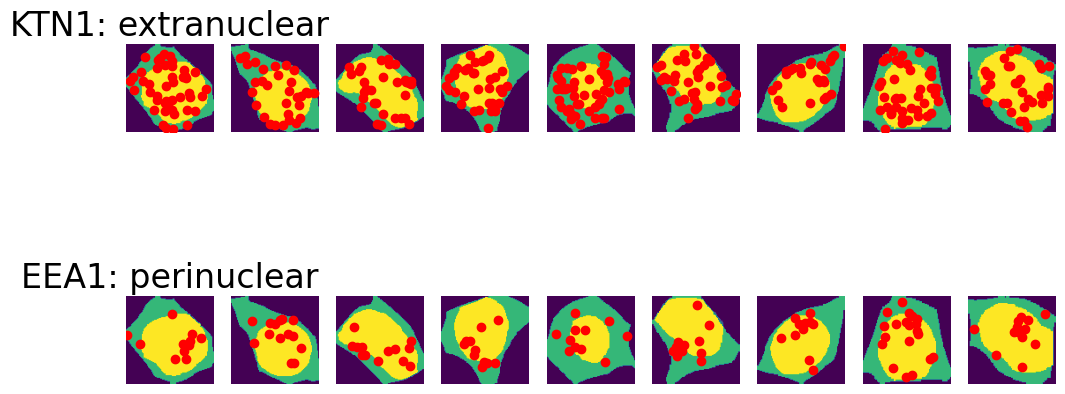

In [637]:
# Now one cell where both are optimized

n_cols = 2
n_max = 9
plt.rcParams["figure.figsize"] = [12, 6]

# First pattern
this_subtype_pattern_scores_gene1 = gene1_subtype_pattern_scores[:, gene1_subtype_pattern_index]
that_subtype_pattern_scores_gene2 = gene2_subtype_pattern_scores[:, gene2_subtype_pattern_index]
joint_arr = this_subtype_pattern_scores_gene1 * that_subtype_pattern_scores_gene2

# take the top X cells scored for this pattern type
idx = np.argpartition(joint_arr, -n_max)[-n_max:]
order = np.argsort(joint_arr[idx])[::-1]
idx = idx[order]
vals = joint_arr[idx]

gene1_to_plot = gene1_adata[idx]
gene2_to_plot = gene2_adata[idx]
    
fig, axs = plt.subplots(2, n_max)
axs[0, 0].set_title(f"{gene1}: {gene1_subytype_pattern}")
axs[1, 0].set_title(f"{gene2}: {gene2_subytype_pattern}")
for i, (tmp_obs1, tmp_obs2) in enumerate(zip(gene1_to_plot, gene2_to_plot)):
    plotFullDataPoint(single_cell_adata[getXYOfSingleCell(tmp_obs1, 0)], ax=axs[0, i])
#     axs[i, 0].set_title(f"{this_subtype_pattern_scores_gene1[idx[i]]:.2f}")
    axs[0, i].axis("off")
    plotFullDataPoint(single_cell_adata[getXYOfSingleCell(tmp_obs2, 0)], ax=axs[1, i])
#     axs[i, 1].set_title(f"{that_subtype_pattern_scores_gene2[idx[i]]:.2f}")
    axs[1, i].axis("off")
# axs[0, 0].set_title(gene1)
# axs[0, 1].set_title(gene2)


In [217]:
adata.write_h5ad("/mnt/data/david/subcellspace_data/apex_validation_data/adata_subcell_embeddings_classified_and_subtypes_v2.h5ad", compression="gzip")